# EECE 490/690 – Applied Ensemble Learning: Random Forests and Boosting
**Dataset B – Heart Disease Prediction** · Member 1 section: Experiment Setup, Part 1 (EDA), Part 2 (Preprocessing)

## Experiment Setup Box

| Field | Value |
|---|---|
| **Dataset (A / B)** | **B** – Heart Failure Prediction (fedesoriano, Kaggle) |
| **Target column and positive class** | `HeartDisease`; positive class = **1** (patient has heart disease) |
| **Dataset size** | 918 patients × 11 features + target |
| **Random seed** | 42 (used for split, CV folds, and all models) |
| **Train/test split** | 80/20, stratified on `HeartDisease` (734 train / 184 test); test set untouched until Part 5 |
| **Primary evaluation metric and reason** | **Recall (positive class)**, with ROC-AUC as secondary. A false negative means a sick patient is sent home untreated, which is far more costly than a false positive (extra tests). ROC-AUC checks that recall is not achieved by simply flagging everyone. |
| **Group members and responsibilities** | **Member 1 – _name_:** setup box, Part 1 EDA, Part 2 preprocessing, shared setup code. **Member 2 – _name_:** Part 3 RF vs. boosting, Part 4 SMOTENC. **Member 3 – _name_:** Part 5 evaluation, Part 6 SHAP, Part 7 conclusions, notebook integration. |

## 0. Environment and data

In [1]:
# Reproducibility: package versions (keep this output in the submitted notebook)
import sys, sklearn, pandas as pd, numpy as np, matplotlib, seaborn as sns
print("python", sys.version.split()[0])
for m in (sklearn, pd, np, matplotlib, sns):
    print(m.__name__, m.__version__)

python 3.13.18
sklearn 1.9.1
pandas 3.0.5
numpy 2.5.3
matplotlib 3.11.2
seaborn 0.13.2


**Getting the data.** Download `heart.csv` from https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction
and upload it to Colab next to `shared_setup.py` (Files panel on the left). Alternatively run the cell below, which uses `kagglehub`.

In [2]:
import os
if not os.path.exists("heart.csv"):
    try:
        import kagglehub, shutil
        path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")
        shutil.copy(os.path.join(path, "heart.csv"), "heart.csv")
    except Exception as e:
        print("Automatic download failed – upload heart.csv manually.", e)
print("heart.csv found:", os.path.exists("heart.csv"))

heart.csv found: True


In [3]:
import matplotlib.pyplot as plt
from shared_setup import *      # SEED, TARGET, NUM_COLS, CAT_COLS, CV, SCORING, load_and_split, build_preprocessor ...

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)

df = pd.read_csv("heart.csv")
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Part 1 – Understanding the Dataset and EDA

### 1.1 Target, feature types, size, class frequencies

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [5]:
feature_types = pd.DataFrame({
    "dtype": df.drop(columns=TARGET).dtypes.astype(str),
    "group": ["numeric" if c in NUM_COLS else "categorical" for c in df.drop(columns=TARGET).columns],
    "n_unique": df.drop(columns=TARGET).nunique(),
})
feature_types

,dtype,group,n_unique
Age,int64,numeric,50
Sex,str,categorical,2
ChestPainType,str,categorical,4
RestingBP,int64,numeric,67
Cholesterol,int64,numeric,222
FastingBS,int64,numeric,2
RestingECG,str,categorical,3
MaxHR,int64,numeric,119
ExerciseAngina,str,categorical,2
Oldpeak,float64,numeric,53


In [6]:
counts = df[TARGET].value_counts().sort_index()
print(pd.DataFrame({"count": counts, "share": (counts / len(df)).round(3)}))

              count  share
HeartDisease              
0               410  0.447
1               508  0.553


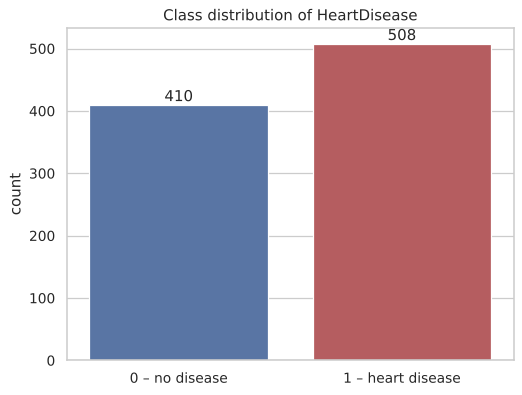

In [7]:
# Visualization 1 – class distribution
ax = sns.countplot(x=TARGET, data=df, hue=TARGET, palette=["#4C72B0", "#C44E52"], legend=False)
ax.set_xticks([0, 1], ["0 – no disease", "1 – heart disease"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Class distribution of HeartDisease"); ax.set_xlabel(""); plt.show()

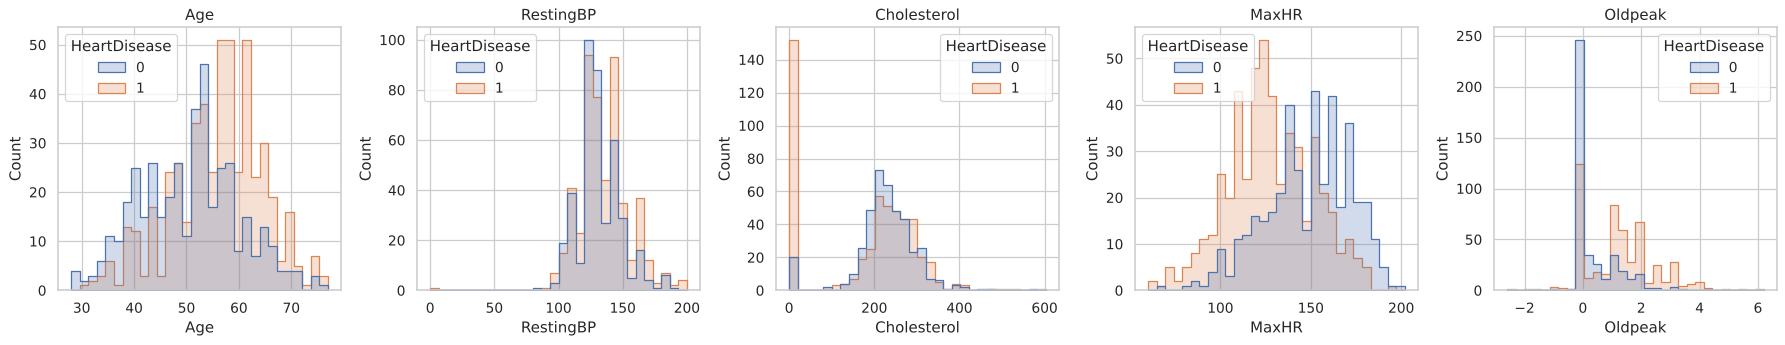

In [8]:
# Visualization 2 – numeric distributions by class (note the spike at 0 in Cholesterol)
num_plot = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, num_plot):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, element="step", ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

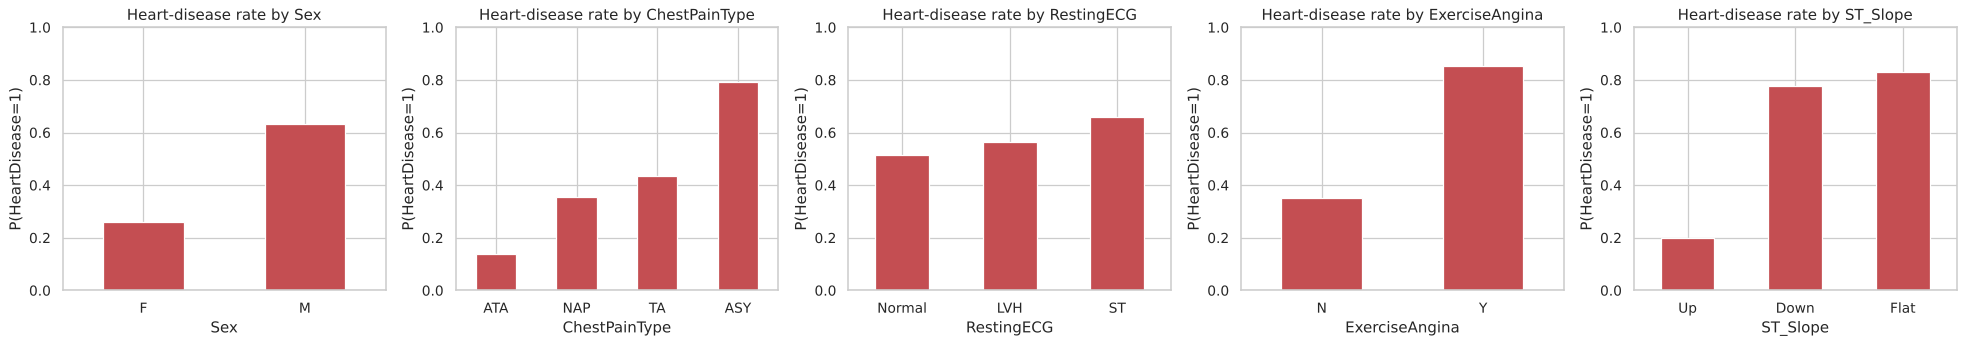

In [9]:
# Visualization 3 – categorical features vs. disease rate
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, CAT_COLS):
    rate = df.groupby(col)[TARGET].mean().sort_values()
    rate.plot.bar(ax=ax, color="#C44E52")
    ax.set_title(f"Heart-disease rate by {col}"); ax.set_ylim(0, 1); ax.set_ylabel("P(HeartDisease=1)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

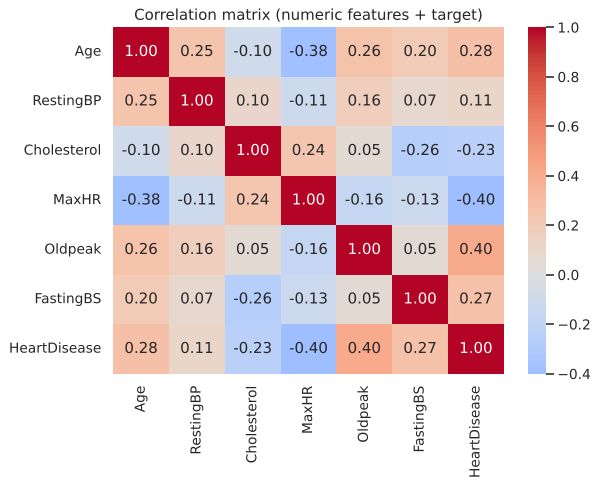

In [10]:
# Visualization 4 – correlation between numeric features and the target
plt.figure(figsize=(7, 5))
sns.heatmap(df[NUM_COLS + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features + target)"); plt.show()

**Interpretation of the EDA**
- **Class balance:** 508 patients with heart disease (55.3%) vs. 410 without (44.7%). The imbalance is mild (ratio ≈ 1.24 : 1), so it is not the main difficulty here; Part 4 tests whether SMOTENC still helps.
- **Strongest categorical signals:** ST_Slope = Flat (82.8% disease) or Down (77.8%) vs. Up (19.7%); ChestPainType = ASY (asymptomatic, 79.0%) vs. ATA (13.9%); ExerciseAngina = Y (85.2%) vs. N (35.1%); males 63.2% vs. females 25.9%.
- **Numeric signals:** sick patients are older (median 57 vs. 51), reach a lower maximum heart rate (median MaxHR 126 vs. 150) and have higher ST depression (median Oldpeak 1.2 vs. 0.0). Correlations with the target: Oldpeak +0.40, MaxHR −0.40, Age +0.28, FastingBS +0.27.
- **Suspicious:** Cholesterol has a *negative* correlation with disease (−0.23), which is the opposite of medical knowledge. The histogram shows why: a large spike at Cholesterol = 0, mostly in the disease class. This is investigated in 1.2.

### 1.2 Data-quality checks: missing, invalid, types, leakage

In [11]:
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64 

Duplicate rows: 0


In [12]:
# Physiologically impossible / suspicious values
checks = {
    "RestingBP == 0": (df["RestingBP"] == 0).sum(),
    "Cholesterol == 0": (df["Cholesterol"] == 0).sum(),
    "Oldpeak < 0": (df["Oldpeak"] < 0).sum(),
    "MaxHR < 60": (df["MaxHR"] < 60).sum(),
}
pd.Series(checks, name="rows")

RestingBP == 0        1
Cholesterol == 0    172
Oldpeak < 0          13
MaxHR < 60            0
Name: rows, dtype: int64

In [13]:
# Are the zero-cholesterol rows different? (important for Part 2)
df["chol_zero"] = (df["Cholesterol"] == 0)
print(df.groupby("chol_zero")[TARGET].agg(["count", "mean"]).rename(columns={"mean": "disease_rate"}))
df = df.drop(columns="chol_zero")

           count  disease_rate
chol_zero                     
False        746      0.477212
True         172      0.883721


In [14]:
# Categorical value check (inconsistent spelling / types)
for c in CAT_COLS:
    print(c, sorted(df[c].unique()))

Sex ['F', 'M']
ChestPainType ['ASY', 'ATA', 'NAP', 'TA']
RestingECG ['LVH', 'Normal', 'ST']
ExerciseAngina ['N', 'Y']
ST_Slope ['Down', 'Flat', 'Up']


**Findings of the data-quality checks**
- **No `NaN` values and no duplicate rows**, but missing data is **hidden as zeros**: Cholesterol = 0 in **172 rows (18.7%)** and RestingBP = 0 in **1 row**. A living patient cannot have a cholesterol or blood pressure of 0, so these mean "not measured".
- **The zeros are not random:** 88.4% of zero-cholesterol patients have heart disease vs. 47.7% of the others, and 126 of the 172 are ASY chest-pain patients. The dataset merges five hospitals (Cleveland, Hungary, Switzerland, Long Beach VA, Statlog), and one source did not record cholesterol, while its patients were mostly sick. So the zero is a **data-collection artifact**, not biology. It also explains the misleading negative cholesterol–disease correlation. A model could learn "cholesterol missing → sick", which would not hold in a new hospital.
- **Oldpeak < 0 in 13 rows** (ST elevation instead of depression). This is clinically possible, so we keep these values.
- **Types are consistent:** 5 string categoricals with clean, consistent labels; 6 numeric columns (FastingBS is binary 0/1). MaxHR has no implausible values (none below 60).
- **Leakage:** no column is derived from the diagnosis itself. ST_Slope and ExerciseAngina are highly predictive, but they are results of an exercise ECG test that is available *before* diagnosis, so they are legitimate features.

### 1.3 Split first, then the DummyClassifier baseline

In [15]:
# Split BEFORE any fitting. The test set is locked away until Part 5.
X_train, X_test, y_train, y_test = load_and_split("heart.csv")
print("train:", X_train.shape, " test:", X_test.shape)
print("train positive rate:", y_train.mean().round(3), " test positive rate:", y_test.mean().round(3))

train: (734, 11)  test: (184, 11)
train positive rate: 0.553  test positive rate: 0.554


In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

dummy = DummyClassifier(strategy="most_frequent")
dummy_cv = cross_validate(dummy, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)
pd.DataFrame([summarize_cv(dummy_cv, "Dummy (most frequent)")]).set_index("model")

,train_accuracy,val_accuracy,train_precision,val_precision,train_recall,val_recall,train_f1,val_f1,train_roc_auc,val_roc_auc
model,,,,,,,,,,
Dummy (most frequent),0.553 +/- 0.001,0.553 +/- 0.002,0.553 +/- 0.001,0.553 +/- 0.002,1.000 +/- 0.000,1.000 +/- 0.000,0.712 +/- 0.001,0.712 +/- 0.001,0.500 +/- 0.000,0.500 +/- 0.000


**Why accuracy is misleading:** the majority class here is "heart disease", so the dummy predicts *every* patient as sick.
It reaches **55.3% accuracy, 100% recall and F1 = 0.71** while having **no ability to tell patients apart (ROC-AUC = 0.50)**,
and it would send all 410 healthy patients for treatment. If the majority class had been "healthy", the same strategy would give a similar accuracy with **0% recall**, missing every sick patient.
Accuracy alone (and even recall alone) therefore says nothing about whether a model is useful. Any real model must beat **ROC-AUC 0.5 and accuracy 0.553** to be worth anything.

### 1.4 Chosen metric
**Recall (sensitivity) for the positive class is primary**: in screening, a missed heart-disease case (false negative) can be fatal,
while a false positive only costs an extra examination. Because recall can be maximised trivially (as the dummy shows), we also report
**ROC-AUC** (ranking quality across thresholds) and **F1** (balance with precision), and we do not accept a model whose ROC-AUC is near 0.5.

## Part 2 – Preprocessing and Data Quality

Both pipelines live in `shared_setup.py` (`build_preprocessor("basic" | "improved")`) so teammates reuse them unchanged.
Every preprocessing step is placed **inside** an sklearn `Pipeline` with the model, so `cross_validate` refits it on each training fold only. This prevents information from the validation fold or test set leaking into the imputation or scaling.

**(i) Basic pipeline**: take the data at face value.
- numeric: `SimpleImputer(median)` (there are no NaN, but it protects against unseen missing values); zeros are kept as real values;
- categorical: `OneHotEncoder(handle_unknown="ignore")`. The categories are nominal, so no order is implied.

**(ii) Improved pipeline**: treat impossible zeros as missing information.
1. `zeros_to_nan`: RestingBP = 0 and Cholesterol = 0 → NaN. This is a fixed rule that learns nothing from the data, so it cannot leak.
2. `StandardScaler`: KNN uses distances, so features must be on the same scale. The scaler ignores NaN while fitting.
3. `KNNImputer(k=5, add_indicator=True)`: fills each missing value with the average of the 5 most similar *training* patients and adds a binary **missingness indicator** column (`missingindicator_Cholesterol`). The "not measured" signal is therefore kept explicitly instead of being hidden inside a fake value of 0.

We do **not** drop the 172 zero-cholesterol rows (18.7% of the data): that would discard valid information in all their other columns and remove mostly positive patients.

*Technique not covered in class (explained in the video):* **KNN imputation with missingness indicators**. A missing value is estimated from similar patients rather than a single global median, and the indicator lets the model know the value was imputed.

*Note:* the single RestingBP = 0 row fell into the **test** set, so the training data has no missing RestingBP. Only a Cholesterol indicator is created (21 output features), and the RestingBP value of that test patient is simply KNN-imputed at prediction time.

In [17]:
pre_basic = build_preprocessor("basic")
pre_improved = build_preprocessor("improved")

# Sanity check: fit on TRAINING data only and inspect output features
pre_improved.fit(X_train)
print(len(pre_improved.get_feature_names_out()), "features after improved preprocessing:")
print(list(pre_improved.get_feature_names_out()))

21 features after improved preprocessing:
['num__Age', 'num__RestingBP', 'num__Cholesterol', 'num__MaxHR', 'num__Oldpeak', 'num__FastingBS', 'num__missingindicator_Cholesterol', 'cat__Sex_F', 'cat__Sex_M', 'cat__ChestPainType_ASY', 'cat__ChestPainType_ATA', 'cat__ChestPainType_NAP', 'cat__ChestPainType_TA', 'cat__RestingECG_LVH', 'cat__RestingECG_Normal', 'cat__RestingECG_ST', 'cat__ExerciseAngina_N', 'cat__ExerciseAngina_Y', 'cat__ST_Slope_Down', 'cat__ST_Slope_Flat', 'cat__ST_Slope_Up']


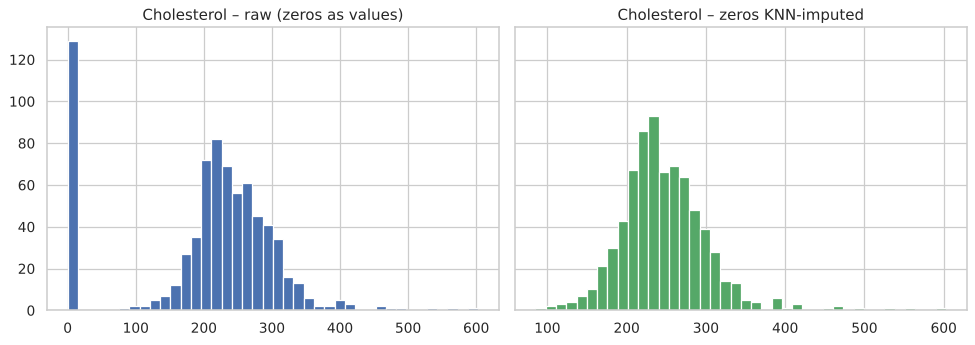

In [18]:
# Show what imputation did to cholesterol (training data only)
Xt = pd.DataFrame(pre_improved.transform(X_train), columns=pre_improved.get_feature_names_out(), index=X_train.index)
scaler = pre_improved.named_transformers_["num"].named_steps["scale"]
chol_idx = NUM_COLS.index("Cholesterol")
chol_imputed = Xt["num__Cholesterol"] * scaler.scale_[chol_idx] + scaler.mean_[chol_idx]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].hist(X_train["Cholesterol"], bins=40); axes[0].set_title("Cholesterol – raw (zeros as values)")
axes[1].hist(chol_imputed, bins=40, color="#55A868"); axes[1].set_title("Cholesterol – zeros KNN-imputed")
plt.tight_layout(); plt.show()

### Fair comparison: same model, only the preprocessing changes
Random Forest with fixed default hyperparameters and `random_state=SEED`, same 3 stratified folds (`CV`) on the **training set only**.

In [19]:
from sklearn.ensemble import RandomForestClassifier

results = [summarize_cv(dummy_cv, "Dummy (most frequent)")]
raw = {}
for kind, pre in [("basic", pre_basic), ("improved", pre_improved)]:
    pipe = Pipeline([("pre", build_preprocessor(kind)),
                     ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))])
    cv_res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)
    raw[kind] = cv_res
    results.append(summarize_cv(cv_res, f"RandomForest + {kind} pipeline"))

part2_table = pd.DataFrame(results).set_index("model")
part2_table[[c for c in part2_table.columns if c.startswith("val_")]]

,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
model,,,,,
Dummy (most frequent),0.553 +/- 0.002,0.553 +/- 0.002,1.000 +/- 0.000,0.712 +/- 0.001,0.500 +/- 0.000
RandomForest + basic pipeline,0.856 +/- 0.017,0.851 +/- 0.012,0.897 +/- 0.054,0.872 +/- 0.020,0.928 +/- 0.012
RandomForest + improved pipeline,0.862 +/- 0.013,0.856 +/- 0.011,0.904 +/- 0.040,0.879 +/- 0.015,0.930 +/- 0.012


In [20]:
# Train vs validation (overfitting check)
part2_table[["train_recall", "val_recall", "train_roc_auc", "val_roc_auc"]]

,train_recall,val_recall,train_roc_auc,val_roc_auc
model,,,,
Dummy (most frequent),1.000 +/- 0.000,1.000 +/- 0.000,0.500 +/- 0.000,0.500 +/- 0.000
RandomForest + basic pipeline,1.000 +/- 0.000,0.897 +/- 0.054,1.000 +/- 0.000,0.928 +/- 0.012
RandomForest + improved pipeline,1.000 +/- 0.000,0.904 +/- 0.040,1.000 +/- 0.000,0.930 +/- 0.012


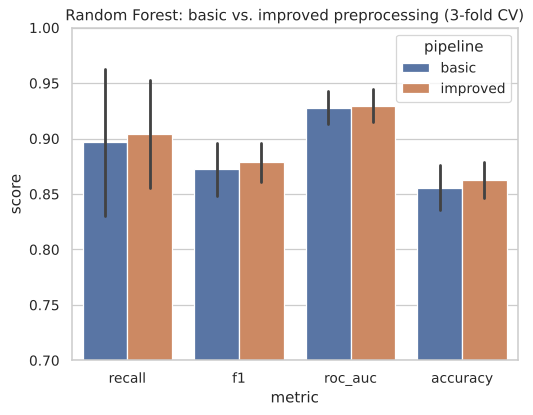

In [21]:
# Visual comparison of validation scores per fold
plot_df = pd.concat([
    pd.DataFrame({"metric": m, "score": raw[k][f"test_{m}"], "pipeline": k})
    for k in raw for m in ["recall", "f1", "roc_auc", "accuracy"]
])
sns.barplot(data=plot_df, x="metric", y="score", hue="pipeline", errorbar="sd")
plt.ylim(0.7, 1.0); plt.title("Random Forest: basic vs. improved preprocessing (3-fold CV)"); plt.show()

### Optional extra: is the missingness indicator itself a shortcut?
Same improved pipeline but **without** the indicator columns. If performance drops noticeably, the model relies on
"cholesterol not recorded" – a hospital artifact that may not transfer to new data (discuss in Part 7 as a deployment risk).

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import KNNImputer

pre_no_ind = ColumnTransformer([
    ("num", Pipeline([("zeros_to_nan", FunctionTransformer(zeros_to_nan, feature_names_out="one-to-one")),
                      ("scale", StandardScaler()),
                      ("impute", KNNImputer(n_neighbors=5, add_indicator=False))]), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
])
pipe = Pipeline([("pre", pre_no_ind),
                 ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))])
cv_res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)
pd.concat([part2_table, pd.DataFrame([summarize_cv(cv_res, "RandomForest + improved, no indicator")]).set_index("model")]) \
  [["val_recall", "val_f1", "val_roc_auc", "val_accuracy"]]

,val_recall,val_f1,val_roc_auc,val_accuracy
model,,,,
Dummy (most frequent),1.000 +/- 0.000,0.712 +/- 0.001,0.500 +/- 0.000,0.553 +/- 0.002
RandomForest + basic pipeline,0.897 +/- 0.054,0.872 +/- 0.020,0.928 +/- 0.012,0.856 +/- 0.017
RandomForest + improved pipeline,0.904 +/- 0.040,0.879 +/- 0.015,0.930 +/- 0.012,0.862 +/- 0.013
"RandomForest + improved, no indicator",0.894 +/- 0.034,0.872 +/- 0.011,0.927 +/- 0.012,0.856 +/- 0.010


**Interpretation of the preprocessing comparison**

| Random Forest (3-fold CV, training set) | val recall | val F1 | val ROC-AUC | val accuracy |
|---|---|---|---|---|
| Dummy (most frequent) | 1.000 | 0.712 | 0.500 | 0.553 |
| Basic pipeline | 0.897 ± 0.054 | 0.872 ± 0.020 | 0.928 ± 0.012 | 0.856 ± 0.017 |
| **Improved pipeline** | **0.904 ± 0.040** | **0.879 ± 0.015** | **0.930 ± 0.012** | **0.862 ± 0.013** |
| Improved, no indicator | 0.894 ± 0.034 | 0.872 ± 0.011 | 0.927 ± 0.012 | 0.856 ± 0.010 |

*(mean ± standard deviation over the 3 folds; full metrics in the tables above)*

- **Both pipelines are far better than the baseline** (ROC-AUC ≈ 0.93 vs. 0.50).
- **The improved pipeline is slightly better on every metric** (recall +0.7 pts, accuracy +0.6 pts, ROC-AUC +0.2 pts) and has **lower fold-to-fold variance**. However, the gains are **smaller than the standard deviation across folds**, so the honest conclusion is that the improvement is small and not statistically clear on 734 training rows. Random Forests split on thresholds, so they already partly isolate "Cholesterol = 0" as its own branch, which limits how much explicit imputation can add.
- **Why we still choose the improved pipeline:** it represents the data correctly (no fake cholesterol of 0), it gives more stable folds, and it matters more for models that are sensitive to the raw values (boosting with shallow trees, and SMOTENC in Part 4, which interpolates between patients: interpolating between a real value and a fake 0 would create impossible synthetic patients).
- **Missingness indicator:** removing it lowers recall from 0.904 to 0.894, F1 from 0.879 to 0.872 and accuracy from 0.862 to 0.856. The model does use "cholesterol was not recorded" as a signal. This helps on this dataset but is a **deployment risk**: in a hospital that always measures cholesterol, the shortcut disappears. We keep the indicator for this assignment but flag it for Part 6 (SHAP) and Part 7 (risks).
- **Overfitting:** the default Random Forest reaches **1.000 on every training metric** while validation accuracy is ≈ 0.86. The trees memorise the training set (unlimited depth, `min_samples_leaf=1`). This is the motivation for tuning `max_depth` and `min_samples_leaf` in Part 3.

**Decision handed to Part 3:** use `build_preprocessor("improved")`.

### Handoff to teammates
Everything Members 2 and 3 need is in `shared_setup.py`:
`SEED` (42), `CV` (3-fold stratified, shuffled), `SCORING`, `NUM_COLS`, `CAT_COLS`, `load_and_split()` (fixed 80/20 split: 734 train / 184 test), `build_preprocessor(kind)`, `build_numeric_pipeline(kind)` (numeric part only, for SMOTENC), `summarize_cv()`.

- **Member 2:** wrap every model as `Pipeline([("pre", build_preprocessor("improved")), ("model", ...)])` and always pass `cv=CV`, `return_train_score=True`. Reference to beat: default RF val recall 0.904, ROC-AUC 0.930. For SMOTENC, apply `build_numeric_pipeline("improved")` to `NUM_COLS`, pass `CAT_COLS` through *un-encoded*, run SMOTENC, then one-hot encode.
- **Member 3:** `X_test` / `y_test` must only be used once, for the final model in Part 5. Use the dummy row above as the baseline in the comparison table.